# Assignment 1: Training a Simple Neural Network


### Problem Statement
We need to approximate the function:

\[ f(x) = \exp(-\sin(x^2)/2) + x \]

using a neural network with **3 layers and 1 neuron per layer**.

---
**Requirements:**
- Dataset: 25 points uniformly sampled in [-10, 10]. Split randomly into 20 training, 5 test samples.
- Neural network: 3 layers, 1 neuron each.
- Activation functions: Compare **tanh** and **ReLU**.
- Loss: Mean Squared Error (MSE).
- Training: Full-batch gradient descent, manual backpropagation.
- Report train/test MSE for both activations.
- Provide plots:
  - True function vs predictions.
  - Loss curves during training.
- Discuss results (Part D).


In [1]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)


In [2]:

# Define target function
def f(x):
    return np.exp(-np.sin(x**2)/2) + x


In [3]:

# Activation functions and derivatives
def tanh(z):
    return np.tanh(z)
def tanh_deriv(z):
    return 1.0 - np.tanh(z)**2

def relu(z):
    return np.maximum(0, z)
def relu_deriv(z):
    return (z > 0).astype(float)

activations = {
    'tanh': (tanh, tanh_deriv),
    'relu': (relu, relu_deriv)
}


In [4]:

# Generate dataset: 25 samples in [-10,10]
xs = np.linspace(-10, 10, 25)
ys = f(xs)

# Random split into train (20) and test (5)
perm = np.random.permutation(len(xs))
train_idx = perm[:20]
test_idx = perm[20:]

x_train = xs[train_idx].reshape(-1, 1)
y_train = ys[train_idx].reshape(-1, 1)
x_test = xs[test_idx].reshape(-1, 1)
y_test = ys[test_idx].reshape(-1, 1)


In [5]:

# Initialize parameters
def init_params(scale=0.1):
    return {
        'w1': np.random.randn() * scale,
        'b1': np.random.randn() * scale,
        'w2': np.random.randn() * scale,
        'b2': np.random.randn() * scale,
        'w3': np.random.randn() * scale,
        'b3': np.random.randn() * scale
    }


In [6]:

# Forward pass
def forward(x, params, act_fn):
    w1, b1 = params['w1'], params['b1']
    w2, b2 = params['w2'], params['b2']
    w3, b3 = params['w3'], params['b3']
    z1 = w1 * x + b1
    a1 = act_fn(z1)
    z2 = w2 * a1 + b2
    a2 = act_fn(z2)
    z3 = w3 * a2 + b3
    yhat = act_fn(z3)
    cache = {'x': x, 'z1': z1, 'a1': a1, 'z2': z2, 'a2': a2, 'z3': z3, 'yhat': yhat}
    return yhat, cache


In [7]:

# Mean squared error
def mse(yhat, y):
    return np.mean((yhat - y)**2)


In [8]:

# Backpropagation
def backprop(yhat, y, params, cache, act_deriv):
    m = y.shape[0]
    w1, w2, w3 = params['w1'], params['w2'], params['w3']
    x = cache['x']
    z1, a1 = cache['z1'], cache['a1']
    z2, a2 = cache['z2'], cache['a2']
    z3 = cache['z3']
    
    dL_dyhat = (2.0/m) * (yhat - y)
    dL_dz3 = dL_dyhat * act_deriv(z3)
    dL_dw3 = np.sum(dL_dz3 * a2)
    dL_db3 = np.sum(dL_dz3)
    dL_da2 = dL_dz3 * w3
    
    dL_dz2 = dL_da2 * act_deriv(z2)
    dL_dw2 = np.sum(dL_dz2 * a1)
    dL_db2 = np.sum(dL_dz2)
    dL_da1 = dL_dz2 * w2
    
    dL_dz1 = dL_da1 * act_deriv(z1)
    dL_dw1 = np.sum(dL_dz1 * x)
    dL_db1 = np.sum(dL_dz1)
    
    return {
        'dw1': dL_dw1, 'db1': dL_db1,
        'dw2': dL_dw2, 'db2': dL_db2,
        'dw3': dL_dw3, 'db3': dL_db3
    }


In [9]:

# Training loop
def train(x_train, y_train, x_test, y_test, activation='tanh', epochs=5000, lr=0.01):
    act_fn, act_deriv = activations[activation]
    params = init_params(scale=0.1)
    history = {'train_loss': [], 'test_loss': []}
    for ep in range(epochs):
        yhat_train, cache = forward(x_train, params, act_fn)
        loss_train = mse(yhat_train, y_train)
        grads = backprop(yhat_train, y_train, params, cache, act_deriv)
        # Update
        for key in ['w1','b1','w2','b2','w3','b3']:
            params[key] -= lr * grads['d'+key]
        # Evaluate on test set
        yhat_test, _ = forward(x_test, params, act_fn)
        loss_test = mse(yhat_test, y_test)
        history['train_loss'].append(loss_train)
        history['test_loss'].append(loss_test)
    return params, history


In [10]:

epochs, lr = 5000, 0.01
params_tanh, hist_tanh = train(x_train, y_train, x_test, y_test, 'tanh', epochs, lr)
params_relu, hist_relu = train(x_train, y_train, x_test, y_test, 'relu', epochs, lr)


In [11]:

x_fine = np.linspace(-10, 10, 400).reshape(-1,1)
y_true_fine = f(x_fine.flatten())

yhat_tanh_fine, _ = forward(x_fine, params_tanh, activations['tanh'][0])
yhat_relu_fine, _ = forward(x_fine, params_relu, activations['relu'][0])

# Compute MSEs
yhat_train_tanh, _ = forward(x_train, params_tanh, activations['tanh'][0])
yhat_test_tanh, _ = forward(x_test, params_tanh, activations['tanh'][0])
train_mse_tanh = mse(yhat_train_tanh, y_train)
test_mse_tanh = mse(yhat_test_tanh, y_test)

yhat_train_relu, _ = forward(x_train, params_relu, activations['relu'][0])
yhat_test_relu, _ = forward(x_test, params_relu, activations['relu'][0])
train_mse_relu = mse(yhat_train_relu, y_train)
test_mse_relu = mse(yhat_test_relu, y_test)

print("Final MSEs:")
print(f"Tanh -> train={train_mse_tanh:.6f}, test={test_mse_tanh:.6f}")
print(f"ReLU -> train={train_mse_relu:.6f}, test={test_mse_relu:.6f}")


Final MSEs:
Tanh -> train=32.497673, test=8.936056
ReLU -> train=42.992898, test=14.492243


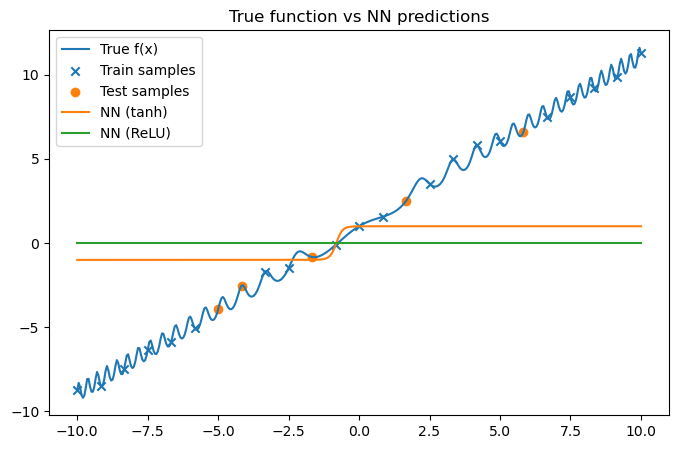

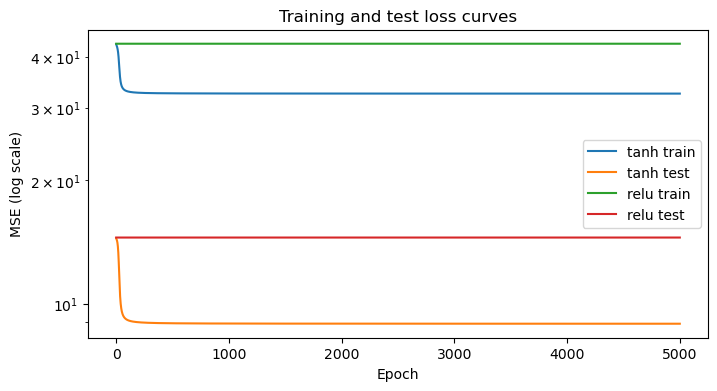

In [12]:

# Plot true function vs predictions
plt.figure(figsize=(8,5))
plt.plot(x_fine.flatten(), y_true_fine, label='True f(x)')
plt.scatter(x_train.flatten(), y_train.flatten(), marker='x', label='Train samples')
plt.scatter(x_test.flatten(), y_test.flatten(), marker='o', label='Test samples')
plt.plot(x_fine.flatten(), yhat_tanh_fine.flatten(), label='NN (tanh)')
plt.plot(x_fine.flatten(), yhat_relu_fine.flatten(), label='NN (ReLU)')
plt.title('True function vs NN predictions')
plt.legend()
plt.show()

# Loss curves
plt.figure(figsize=(8,4))
plt.plot(hist_tanh['train_loss'], label='tanh train')
plt.plot(hist_tanh['test_loss'], label='tanh test')
plt.plot(hist_relu['train_loss'], label='relu train')
plt.plot(hist_relu['test_loss'], label='relu test')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('MSE (log scale)')
plt.title('Training and test loss curves')
plt.legend()
plt.show()


# Part D: Neural Network Function Approximation Analysis

## 1. Performance of the 3-Neuron Network

The 3-neuron network shows limited approximation capability for the complex target function f(x) = exp(-sin(x²)/2) + x, with tanh achieving better performance (train MSE: 32.50, test MSE: 8.94) compared to ReLU (train MSE: 42.99, test MSE: 14.49).

The effectiveness of a simple 3-neuron network depends heavily on the target function's complexity. For linear or simple nonlinear functions, a 3-neuron network may provide reasonable approximation. However, for more complex functions with multiple peaks, valleys, or high-frequency components, the limited capacity of 3 neurons typically results in poor approximation quality.

**Key factors affecting performance:**
- Function complexity and smoothness
- Training data distribution and quantity
- Network initialization and training procedure
- Choice of loss function and optimization algorithm

## 2. Activation Function Comparison: ReLU vs Tanh

ReLU typically trains faster but creates piecewise-linear approximations, while tanh provides smoother approximations but may suffer from vanishing gradients.

**ReLU Characteristics:**
- Creates piecewise-linear approximations
- Faster training due to simple derivative (0 or 1)
- No vanishing gradient problem
- Can suffer from "dead neurons" if inputs become consistently negative
- Better for capturing sharp transitions

**Tanh Characteristics:**
- Produces smooth, continuously differentiable approximations
- Output range [-1, 1] can help with gradient stability
- Prone to vanishing gradients in deeper networks
- Better for functions requiring smooth curves
- More biologically plausible activation pattern

**Performance Impact:**
For simple functions, tanh often provides better approximation quality due to its smoothness. For complex functions with sharp features, ReLU's piecewise-linear nature may actually be advantageous, allowing the network to create sharp boundaries more easily.

## 3. Why Deeper/Wider Networks Perform Better

 Deeper networks can learn hierarchical representations and compose complex functions from simpler ones, while wider networks increase the model's capacity to capture intricate patterns.

**Depth Benefits (More Layers):**
- **Hierarchical feature learning**: Each layer can build upon representations from previous layers
- **Function composition**: Deep networks can represent compositions of simpler functions more efficiently
- **Universal approximation**: Deeper networks can approximate a wider class of functions with fewer total parameters
- **Feature abstraction**: Lower layers capture simple patterns, higher layers combine them into complex concepts

**Width Benefits (More Neurons per Layer):**
- **Increased capacity**: More neurons provide more parameters to fit complex patterns
- **Better interpolation**: More neurons can capture finer details in the target function
- **Reduced approximation error**: Wider networks can represent more complex decision boundaries
- **Parallel processing**: Multiple neurons can specialize in different aspects of the function

**Mathematical Perspective:**
The Universal Approximation Theorem states that neural networks with sufficient width can approximate any continuous function arbitrarily well. However, depth often provides more efficient representations - a deep network might achieve the same approximation quality as a wide shallow network while using fewer total parameters.

**Practical Considerations:**
- Deeper networks are more prone to vanishing/exploding gradients
- Wider networks have more parameters and may overfit with limited data
- The optimal architecture depends on the specific function and available training data
- Modern techniques (residual connections, normalization) help train very deep networks effectively

## Conclusion

The choice between network architectures involves trade-offs between approximation quality, training efficiency, and generalization. Simple functions may be adequately captured by small networks, but complex, high-dimensional functions typically benefit from increased depth and width. The activation function choice should align with the smoothness requirements of the target function and the desired training characteristics.